In [2]:
import pandas as pd

df = pd.read_csv('../data/2018-19.csv')
print(df.shape)
df.head()


(380, 62)


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSCH,PSCD,PSCA
0,E0,10/08/2018,Man United,Leicester,2,1,H,1,0,H,...,1.79,17,-0.75,1.75,1.70,2.29,2.21,1.55,4.07,7.69
1,E0,11/08/2018,Bournemouth,Cardiff,2,0,H,1,0,H,...,1.83,20,-0.75,2.20,2.13,1.80,1.75,1.88,3.61,4.70
2,E0,11/08/2018,Fulham,Crystal Palace,0,2,A,0,1,A,...,1.87,22,-0.25,2.18,2.11,1.81,1.77,2.62,3.38,2.90
3,E0,11/08/2018,Huddersfield,Chelsea,0,3,A,0,2,A,...,1.84,23,1.00,1.84,1.80,2.13,2.06,7.24,3.95,1.58
4,E0,11/08/2018,Newcastle,Tottenham,1,2,A,1,2,A,...,1.81,20,0.25,2.20,2.12,1.80,1.76,4.74,3.53,1.89


In [3]:
print(df.columns.tolist())


['Div', 'Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'Referee', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'VCH', 'VCD', 'VCA', 'Bb1X2', 'BbMxH', 'BbAvH', 'BbMxD', 'BbAvD', 'BbMxA', 'BbAvA', 'BbOU', 'BbMx>2.5', 'BbAv>2.5', 'BbMx<2.5', 'BbAv<2.5', 'BbAH', 'BbAHh', 'BbMxAHH', 'BbAvAHH', 'BbMxAHA', 'BbAvAHA', 'PSCH', 'PSCD', 'PSCA']


In [5]:
import pandas as pd
import os

# Load all seasons
data_folder = '../data/'
all_seasons = []

for file in os.listdir(data_folder):
    if file.endswith('.csv'):
        df = pd.read_csv(data_folder + file)
        df['Season'] = file.replace('.csv', '')  # add season column
        all_seasons.append(df)

# Combine all seasons
df = pd.concat(all_seasons, ignore_index=True)
print(f"Total matches: {len(df)}")
print(f"Seasons: {df['Season'].unique()}")
df.head()

Total matches: 3040
Seasons: ['2018-19' '2019-20' '2020-21' '2021-22' '2022-23' '2023-24' '2024-25'
 '2025-26']


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA
0,E0,10/08/2018,Man United,Leicester,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,11/08/2018,Bournemouth,Cardiff,2,0,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,11/08/2018,Fulham,Crystal Palace,0,2,A,0,1,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,11/08/2018,Huddersfield,Chelsea,0,3,A,0,2,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,11/08/2018,Newcastle,Tottenham,1,2,A,1,2,A,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Convert date to datetime and sort
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date').reset_index(drop=True)

print(f"First match: {df['Date'].min()}")
print(f"Last match: {df['Date'].max()}")
df[['Date', 'HomeTeam', 'AwayTeam', 'FTR']].head(10)

First match: 2018-08-10 00:00:00
Last match: 2026-05-24 00:00:00


,Date,HomeTeam,AwayTeam,FTR
0,2018-08-10,Man United,Leicester,H
1,2018-08-11,Bournemouth,Cardiff,H
2,2018-08-11,Fulham,Crystal Palace,A
3,2018-08-11,Huddersfield,Chelsea,A
4,2018-08-11,Newcastle,Tottenham,A
5,2018-08-11,Watford,Brighton,H
6,2018-08-11,Wolves,Everton,D
7,2018-08-12,Arsenal,Man City,A
8,2018-08-12,Liverpool,West Ham,H
9,2018-08-12,Southampton,Burnley,D


In [7]:
# Keep only the columns we need
df = df[['Date', 'Season', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 
         'B365H', 'B365D', 'B365A']]

print(df.shape)
df.head()

(3040, 10)


,Date,Season,HomeTeam,AwayTeam,FTHG,FTAG,FTR,B365H,B365D,B365A
0,2018-08-10,2018-19,Man United,Leicester,2,1,H,1.57,3.9,7.50
1,2018-08-11,2018-19,Bournemouth,Cardiff,2,0,H,1.90,3.6,4.50
2,2018-08-11,2018-19,Fulham,Crystal Palace,0,2,A,2.50,3.4,3.00
3,2018-08-11,2018-19,Huddersfield,Chelsea,0,3,A,6.50,4.0,1.61
4,2018-08-11,2018-19,Newcastle,Tottenham,1,2,A,3.90,3.5,2.04


In [8]:
def get_team_form(df, team, date, n=5):
    # Get last n matches for a team before a given date
    team_matches = df[
        ((df['HomeTeam'] == team) | (df['AwayTeam'] == team)) &
        (df['Date'] < date)
    ].tail(n)
    
    if len(team_matches) == 0:
        return {'wins': 0, 'draws': 0, 'losses': 0, 'goals_scored': 0, 'goals_conceded': 0}
    
    wins, draws, losses = 0, 0, 0
    goals_scored, goals_conceded = 0, 0
    
    for _, match in team_matches.iterrows():
        if match['HomeTeam'] == team:
            goals_scored += match['FTHG']
            goals_conceded += match['FTAG']
            if match['FTR'] == 'H': wins += 1
            elif match['FTR'] == 'D': draws += 1
            else: losses += 1
        else:
            goals_scored += match['FTAG']
            goals_conceded += match['FTHG']
            if match['FTR'] == 'A': wins += 1
            elif match['FTR'] == 'D': draws += 1
            else: losses += 1
    
    return {
        'wins': wins,
        'draws': draws, 
        'losses': losses,
        'goals_scored': goals_scored,
        'goals_conceded': goals_conceded
    }

# Test it
print(get_team_form(df, 'Arsenal', pd.Timestamp('2023-01-01')))

{'wins': 5, 'draws': 0, 'losses': 0, 'goals_scored': 15, 'goals_conceded': 3}


In [9]:
features = []

for idx, row in df.iterrows():
    home_form = get_team_form(df, row['HomeTeam'], row['Date'])
    away_form = get_team_form(df, row['AwayTeam'], row['Date'])
    
    features.append({
        'home_wins': home_form['wins'],
        'home_draws': home_form['draws'],
        'home_losses': home_form['losses'],
        'home_goals_scored': home_form['goals_scored'],
        'home_goals_conceded': home_form['goals_conceded'],
        'away_wins': away_form['wins'],
        'away_draws': away_form['draws'],
        'away_losses': away_form['losses'],
        'away_goals_scored': away_form['goals_scored'],
        'away_goals_conceded': away_form['goals_conceded'],
        'b365_home': row['B365H'],
        'b365_draw': row['B365D'],
        'b365_away': row['B365A'],
        'result': row['FTR']
    })

features_df = pd.DataFrame(features)
print(features_df.shape)
features_df.head()

(3040, 14)


,home_wins,home_draws,home_losses,home_goals_scored,home_goals_conceded,away_wins,away_draws,away_losses,away_goals_scored,away_goals_conceded,b365_home,b365_draw,b365_away,result
0,0,0,0,0,0,0,0,0,0,0,1.57,3.9,7.50,H
1,0,0,0,0,0,0,0,0,0,0,1.90,3.6,4.50,H
2,0,0,0,0,0,0,0,0,0,0,2.50,3.4,3.00,A
3,0,0,0,0,0,0,0,0,0,0,6.50,4.0,1.61,A
4,0,0,0,0,0,0,0,0,0,0,3.90,3.5,2.04,A


In [10]:
# Add date back to features_df for splitting
features_df['Date'] = df['Date'].values

# Split by date - use last season as test
split_date = pd.Timestamp('2024-08-01')

train = features_df[features_df['Date'] < split_date].drop('Date', axis=1)
test = features_df[features_df['Date'] >= split_date].drop('Date', axis=1)

print(f"Training matches: {len(train)}")
print(f"Test matches: {len(test)}")
print(f"\nResult distribution in training:")
print(train['result'].value_counts())

Training matches: 2280
Test matches: 760

Result distribution in training:
result
H    1019
A     758
D     503
Name: count, dtype: int64


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Split features and target
X_train = train.drop('result', axis=1)
y_train = train['result']
X_test = test.drop('result', axis=1)
y_test = test['result']

# Train Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Evaluate
y_pred = rf.predict(X_test)
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Random Forest Accuracy: 0.492

Classification Report:
              precision    recall  f1-score   support

           A       0.47      0.51      0.49       246
           D       0.26      0.05      0.08       197
           H       0.52      0.76      0.62       317

    accuracy                           0.49       760
   macro avg       0.42      0.44      0.39       760
weighted avg       0.44      0.49      0.44       760



In [12]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder

# XGBoost needs numeric labels
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# Train XGBoost
xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train_enc)

# Evaluate
y_pred_xgb = le.inverse_transform(xgb_model.predict(X_test))
print(f"XGBoost Accuracy: {accuracy_score(y_test, y_pred_xgb):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.483

Classification Report:
              precision    recall  f1-score   support

           A       0.51      0.49      0.50       246
           D       0.27      0.12      0.16       197
           H       0.51      0.71      0.59       317

    accuracy                           0.48       760
   macro avg       0.43      0.44      0.42       760
weighted avg       0.45      0.48      0.45       760



In [13]:
# Convert odds to implied probability
features_df['prob_home'] = 1 / features_df['b365_home']
features_df['prob_draw'] = 1 / features_df['b365_draw']
features_df['prob_away'] = 1 / features_df['b365_away']

# Normalise so they sum to 1
total = features_df['prob_home'] + features_df['prob_draw'] + features_df['prob_away']
features_df['prob_home'] /= total
features_df['prob_draw'] /= total
features_df['prob_away'] /= total

features_df[['prob_home', 'prob_draw', 'prob_away']].head()

,prob_home,prob_draw,prob_away
0,0.620387,0.249745,0.129868
1,0.512821,0.270655,0.216524
2,0.389313,0.286260,0.324427
3,0.150099,0.243911,0.605990
4,0.248382,0.276769,0.474849


In [14]:
# Add date back for splitting
features_df['Date'] = df['Date'].values

# Split again with new features
train2 = features_df[features_df['Date'] < split_date].drop(['Date', 'b365_home', 'b365_draw', 'b365_away'], axis=1)
test2 = features_df[features_df['Date'] >= split_date].drop(['Date', 'b365_home', 'b365_draw', 'b365_away'], axis=1)

X_train2 = train2.drop('result', axis=1)
y_train2 = train2['result']
X_test2 = test2.drop('result', axis=1)
y_test2 = test2['result']

# Random Forest
rf2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf2.fit(X_train2, y_train2)
y_pred_rf2 = rf2.predict(X_test2)
print(f"Random Forest Accuracy: {accuracy_score(y_test2, y_pred_rf2):.3f}")

# XGBoost
y_train2_enc = le.fit_transform(y_train2)
xgb2 = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss')
xgb2.fit(X_train2, y_train2_enc)
y_pred_xgb2 = le.inverse_transform(xgb2.predict(X_test2))
print(f"XGBoost Accuracy: {accuracy_score(y_test2, y_pred_xgb2):.3f}")

Random Forest Accuracy: 0.497
XGBoost Accuracy: 0.470


In [15]:
def get_team_form_v2(df, team, date, n=5):
    # All matches before this date
    team_matches = df[
        ((df['HomeTeam'] == team) | (df['AwayTeam'] == team)) &
        (df['Date'] < date)
    ].tail(n)
    
    # Home matches only
    home_matches = df[
        (df['HomeTeam'] == team) &
        (df['Date'] < date)
    ].tail(n)
    
    # Away matches only
    away_matches = df[
        (df['AwayTeam'] == team) &
        (df['Date'] < date)
    ].tail(n)
    
    def calc_stats(matches, team):
        wins, draws, losses = 0, 0, 0
        goals_scored, goals_conceded = 0, 0
        for _, match in matches.iterrows():
            if match['HomeTeam'] == team:
                goals_scored += match['FTHG']
                goals_conceded += match['FTAG']
                if match['FTR'] == 'H': wins += 1
                elif match['FTR'] == 'D': draws += 1
                else: losses += 1
            else:
                goals_scored += match['FTAG']
                goals_conceded += match['FTHG']
                if match['FTR'] == 'A': wins += 1
                elif match['FTR'] == 'D': draws += 1
                else: losses += 1
        return wins, draws, losses, goals_scored, goals_conceded
    
    w, d, l, gs, gc = calc_stats(team_matches, team)
    hw, hd, hl, hgs, hgc = calc_stats(home_matches, team)
    aw, ad, al, ags, agc = calc_stats(away_matches, team)
    
    return {
        'wins': w, 'draws': d, 'losses': l,
        'goals_scored': gs, 'goals_conceded': gc,
        'home_wins': hw, 'home_goals_scored': hgs, 'home_goals_conceded': hgc,
        'away_wins': aw, 'away_goals_scored': ags, 'away_goals_conceded': agc
    }

print(get_team_form_v2(df, 'Arsenal', pd.Timestamp('2023-01-01')))

{'wins': 5, 'draws': 0, 'losses': 0, 'goals_scored': 15, 'goals_conceded': 3, 'home_wins': 5, 'home_goals_scored': 16, 'home_goals_conceded': 5, 'away_wins': 4, 'away_goals_scored': 9, 'away_goals_conceded': 3}


In [16]:
features2 = []

for idx, row in df.iterrows():
    home_form = get_team_form_v2(df, row['HomeTeam'], row['Date'])
    away_form = get_team_form_v2(df, row['AwayTeam'], row['Date'])
    
    features2.append({
        # Overall form
        'home_wins': home_form['wins'],
        'home_draws': home_form['draws'],
        'home_losses': home_form['losses'],
        'home_goals_scored': home_form['goals_scored'],
        'home_goals_conceded': home_form['goals_conceded'],
        # Home specific form
        'home_home_wins': home_form['home_wins'],
        'home_home_goals_scored': home_form['home_goals_scored'],
        'home_home_goals_conceded': home_form['home_goals_conceded'],
        # Overall away team form
        'away_wins': away_form['wins'],
        'away_draws': away_form['draws'],
        'away_losses': away_form['losses'],
        'away_goals_scored': away_form['goals_scored'],
        'away_goals_conceded': away_form['goals_conceded'],
        # Away specific form
        'away_away_wins': away_form['away_wins'],
        'away_away_goals_scored': away_form['away_goals_scored'],
        'away_away_goals_conceded': away_form['away_goals_conceded'],
        # Odds as implied probabilities
        'prob_home': 1 / row['B365H'],
        'prob_draw': 1 / row['B365D'],
        'prob_away': 1 / row['B365A'],
        'result': row['FTR']
    })

features2_df = pd.DataFrame(features2)

# Normalise probabilities
total = features2_df['prob_home'] + features2_df['prob_draw'] + features2_df['prob_away']
features2_df['prob_home'] /= total
features2_df['prob_draw'] /= total
features2_df['prob_away'] /= total

print(features2_df.shape)
features2_df.head()

(3040, 20)


,home_wins,home_draws,home_losses,home_goals_scored,home_goals_conceded,home_home_wins,home_home_goals_scored,home_home_goals_conceded,away_wins,away_draws,away_losses,away_goals_scored,away_goals_conceded,away_away_wins,away_away_goals_scored,away_away_goals_conceded,prob_home,prob_draw,prob_away,result
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.620387,0.249745,0.129868,H
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.512821,0.270655,0.216524,H
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.389313,0.286260,0.324427,A
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.150099,0.243911,0.605990,A
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.248382,0.276769,0.474849,A


In [17]:
# Split
features2_df['Date'] = df['Date'].values
train3 = features2_df[features2_df['Date'] < split_date].drop('Date', axis=1)
test3 = features2_df[features2_df['Date'] >= split_date].drop('Date', axis=1)

X_train3 = train3.drop('result', axis=1)
y_train3 = train3['result']
X_test3 = test3.drop('result', axis=1)
y_test3 = test3['result']

# Random Forest
rf3 = RandomForestClassifier(n_estimators=100, random_state=42)
rf3.fit(X_train3, y_train3)
y_pred_rf3 = rf3.predict(X_test3)
print(f"Random Forest Accuracy: {accuracy_score(y_test3, y_pred_rf3):.3f}")

# XGBoost
y_train3_enc = le.fit_transform(y_train3)
xgb3 = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss')
xgb3.fit(X_train3, y_train3_enc)
y_pred_xgb3 = le.inverse_transform(xgb3.predict(X_test3))
print(f"XGBoost Accuracy: {accuracy_score(y_test3, y_pred_xgb3):.3f}")

Random Forest Accuracy: 0.488
XGBoost Accuracy: 0.457


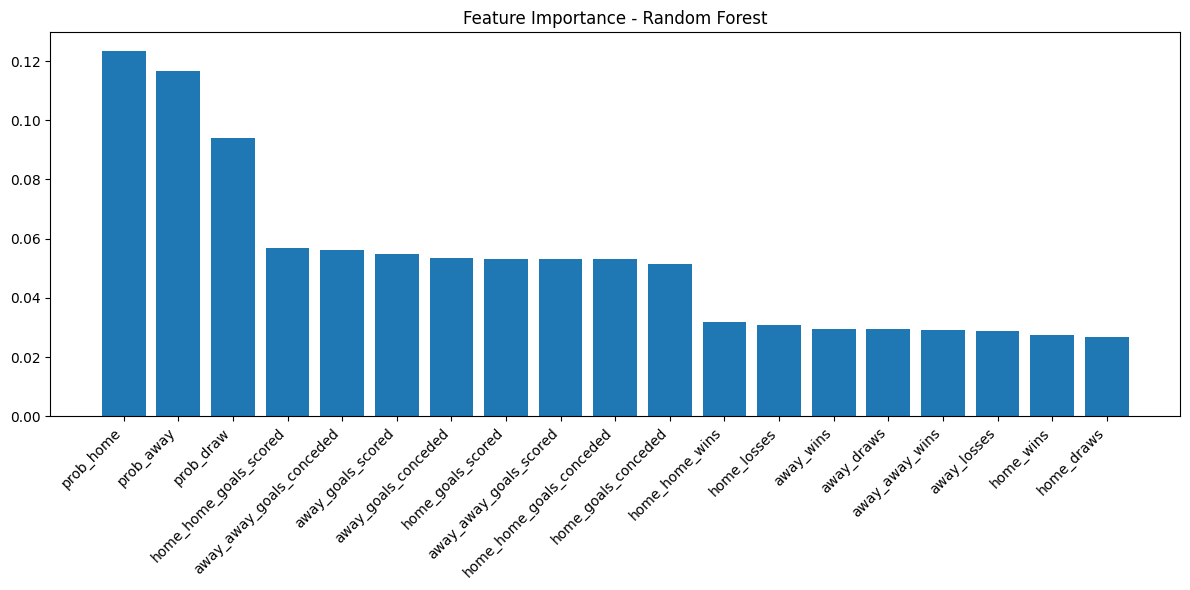

In [18]:
import matplotlib.pyplot as plt

# Feature importance from Random Forest
importances = rf3.feature_importances_
feature_names = X_train3.columns

# Sort by importance
indices = importances.argsort()[::-1]

plt.figure(figsize=(12, 6))
plt.bar(range(len(importances)), importances[indices])
plt.xticks(range(len(importances)), [feature_names[i] for i in indices], rotation=45, ha='right')
plt.title('Feature Importance - Random Forest')
plt.tight_layout()
plt.show()

In [19]:
X_train_odds = train3[['prob_home', 'prob_draw', 'prob_away']]
X_test_odds = test3[['prob_home', 'prob_draw', 'prob_away']]

rf_odds = RandomForestClassifier(n_estimators=100, random_state=42)
rf_odds.fit(X_train_odds, y_train3)
y_pred_odds = rf_odds.predict(X_test_odds)
print(f"Odds only accuracy: {accuracy_score(y_test3, y_pred_odds):.3f}")

Odds only accuracy: 0.459


In [20]:
def get_team_points(df, team, date):
    # Get all matches before this date
    home_matches = df[(df['HomeTeam'] == team) & (df['Date'] < date)]
    away_matches = df[(df['AwayTeam'] == team) & (df['Date'] < date)]
    
    points = 0
    
    for _, match in home_matches.iterrows():
        if match['FTR'] == 'H': points += 3
        elif match['FTR'] == 'D': points += 1
    
    for _, match in away_matches.iterrows():
        if match['FTR'] == 'A': points += 3
        elif match['FTR'] == 'D': points += 1
    
    return points

# Test it
print(get_team_points(df, 'Arsenal', pd.Timestamp('2023-01-01')))

299


In [24]:
def get_team_points_this_season(df, team, date, season):
    home_matches = df[
        (df['HomeTeam'] == team) & 
        (df['Date'] < date) & 
        (df['Season'] == season)
    ]
    away_matches = df[
        (df['AwayTeam'] == team) & 
        (df['Date'] < date) & 
        (df['Season'] == season)
    ]
    
    points = 0
    goal_diff = 0
    
    for _, match in home_matches.iterrows():
        if match['FTR'] == 'H': points += 3
        elif match['FTR'] == 'D': points += 1
        goal_diff += match['FTHG'] - match['FTAG']
    
    for _, match in away_matches.iterrows():
        if match['FTR'] == 'A': points += 3
        elif match['FTR'] == 'D': points += 1
        goal_diff += match['FTAG'] - match['FTHG']
    
    return points, goal_diff

# Test it
print(get_team_points_this_season(df, 'Arsenal', pd.Timestamp('2023-01-01'), '2022-23'))

(43, 26)


In [25]:
features3 = []

for idx, row in df.iterrows():
    home_form = get_team_form_v2(df, row['HomeTeam'], row['Date'])
    away_form = get_team_form_v2(df, row['AwayTeam'], row['Date'])
    home_points, home_gd = get_team_points_this_season(df, row['HomeTeam'], row['Date'], row['Season'])
    away_points, away_gd = get_team_points_this_season(df, row['AwayTeam'], row['Date'], row['Season'])
    
    # Implied probabilities from odds
    prob_home = 1 / row['B365H']
    prob_draw = 1 / row['B365D']
    prob_away = 1 / row['B365A']
    total = prob_home + prob_draw + prob_away
    
    features3.append({
        'home_wins': home_form['wins'],
        'home_draws': home_form['draws'],
        'home_losses': home_form['losses'],
        'home_goals_scored': home_form['goals_scored'],
        'home_goals_conceded': home_form['goals_conceded'],
        'home_home_wins': home_form['home_wins'],
        'home_home_goals_scored': home_form['home_goals_scored'],
        'home_home_goals_conceded': home_form['home_goals_conceded'],
        'away_wins': away_form['wins'],
        'away_draws': away_form['draws'],
        'away_losses': away_form['losses'],
        'away_goals_scored': away_form['goals_scored'],
        'away_goals_conceded': away_form['goals_conceded'],
        'away_away_wins': away_form['away_wins'],
        'away_away_goals_scored': away_form['away_goals_scored'],
        'away_away_goals_conceded': away_form['away_goals_conceded'],
        'home_points': home_points,
        'home_goal_diff': home_gd,
        'away_points': away_points,
        'away_goal_diff': away_gd,
        'prob_home': prob_home / total,
        'prob_draw': prob_draw / total,
        'prob_away': prob_away / total,
        'result': row['FTR']
    })

features3_df = pd.DataFrame(features3)
print(features3_df.shape)
features3_df.head()

(3040, 24)


,home_wins,home_draws,home_losses,home_goals_scored,home_goals_conceded,home_home_wins,home_home_goals_scored,home_home_goals_conceded,away_wins,away_draws,...,away_away_goals_scored,away_away_goals_conceded,home_points,home_goal_diff,away_points,away_goal_diff,prob_home,prob_draw,prob_away,result
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0.620387,0.249745,0.129868,H
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0.512821,0.270655,0.216524,H
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0.389313,0.286260,0.324427,A
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0.150099,0.243911,0.605990,A
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0.248382,0.276769,0.474849,A


In [26]:
# Split
features3_df['Date'] = df['Date'].values
train4 = features3_df[features3_df['Date'] < split_date].drop('Date', axis=1)
test4 = features3_df[features3_df['Date'] >= split_date].drop('Date', axis=1)

X_train4 = train4.drop('result', axis=1)
y_train4 = train4['result']
X_test4 = test4.drop('result', axis=1)
y_test4 = test4['result']

# Random Forest
rf4 = RandomForestClassifier(n_estimators=100, random_state=42)
rf4.fit(X_train4, y_train4)
y_pred_rf4 = rf4.predict(X_test4)
print(f"Random Forest Accuracy: {accuracy_score(y_test4, y_pred_rf4):.3f}")

# XGBoost
y_train4_enc = le.fit_transform(y_train4)
xgb4 = xgb.XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss')
xgb4.fit(X_train4, y_train4_enc)
y_pred_xgb4 = le.inverse_transform(xgb4.predict(X_test4))
print(f"XGBoost Accuracy: {accuracy_score(y_test4, y_pred_xgb4):.3f}")

Random Forest Accuracy: 0.491
XGBoost Accuracy: 0.496


In [27]:
xgb5 = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss'
)
xgb5.fit(X_train4, y_train4_enc)
y_pred_xgb5 = le.inverse_transform(xgb5.predict(X_test4))
print(f"XGBoost Tuned Accuracy: {accuracy_score(y_test4, y_pred_xgb5):.3f}")

XGBoost Tuned Accuracy: 0.484


In [28]:
# Baseline - always predict home win
baseline = ['H'] * len(y_test4)
print(f"Baseline (always predict H): {accuracy_score(y_test4, baseline):.3f}")

# Baseline - always predict bookmaker favourite
def predict_favourite(row):
    if row['prob_home'] > row['prob_draw'] and row['prob_home'] > row['prob_away']:
        return 'H'
    elif row['prob_away'] > row['prob_draw'] and row['prob_away'] > row['prob_home']:
        return 'A'
    else:
        return 'D'

bookie_pred = test4.apply(predict_favourite, axis=1)
print(f"Baseline (bookmaker favourite): {accuracy_score(y_test4, bookie_pred):.3f}")

Baseline (always predict H): 0.417
Baseline (bookmaker favourite): 0.513


In [29]:
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Neural networks need scaled features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train4)
X_test_scaled = scaler.transform(X_test4)

# Encode labels as numbers
le_nn = LabelEncoder()
y_train_nn = le_nn.fit_transform(y_train4)
y_test_nn = le_nn.transform(y_test4)

# Build the model
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(3, activation='softmax')  # 3 outputs: H, D, A
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

c:\Users\Elias Bostrom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,195 (16.39 KB)

 Trainable params: 4,195 (16.39 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
history = model.fit(
    X_train_scaled, y_train_nn,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4265 - loss: 1.0900 - val_accuracy: 0.5899 - val_loss: 1.0021
Epoch 2/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5208 - loss: 1.0180 - val_accuracy: 0.5877 - val_loss: 0.9655
Epoch 3/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5132 - loss: 1.0042 - val_accuracy: 0.5899 - val_loss: 0.9548
Epoch 4/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5230 - loss: 0.9979 - val_accuracy: 0.5965 - val_loss: 0.9453
Epoch 5/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5411 - loss: 0.9916 - val_accuracy: 0.6009 - val_loss: 0.9371
Epoch 6/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5543 - loss: 0.9736 - val_accuracy: 0.6009 - val_loss: 0.9264
Epoch 7/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5444 - loss: 0.9739 - val_accuracy: 0.5943 - val_loss: 0.9261
Epoch 8/100
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5493 - loss: 0.9682 - val_accuracy: 0.5921 - 

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Neural Network Accuracy: 0.482


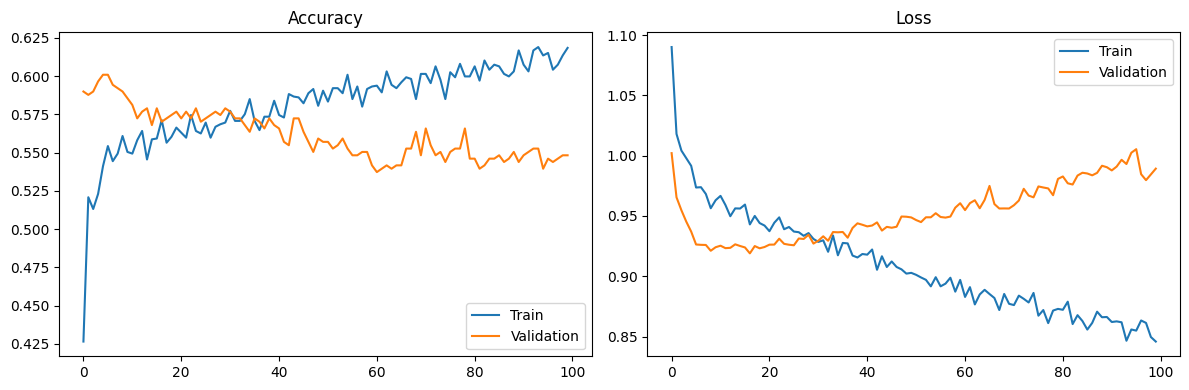

In [31]:
# Evaluate on test set
y_pred_nn = le_nn.inverse_transform(model.predict(X_test_scaled).argmax(axis=1))
print(f"Neural Network Accuracy: {accuracy_score(y_test4, y_pred_nn):.3f}")

# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
# Reset model
model2 = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(3, activation='softmax')
])

model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Early stopping - stop when val_accuracy stops improving
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True
)

history2 = model2.fit(
    X_train_scaled, y_train_nn,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)

y_pred_nn2 = le_nn.inverse_transform(model2.predict(X_test_scaled).argmax(axis=1))
print(f"Neural Network (Early Stopping) Accuracy: {accuracy_score(y_test4, y_pred_nn2):.3f}")
print(f"Stopped at epoch: {len(history2.history['accuracy'])}")

c:\Users\Elias Bostrom\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Neural Network (Early Stopping) Accuracy: 0.496
Stopped at epoch: 19


In [33]:
# Get probability estimates from Random Forest
rf4_probs = rf4.predict_proba(X_test4)
print(f"Classes: {rf4.classes_}")
print(rf4_probs[:5])


Classes: ['A' 'D' 'H']
[[0.21 0.12 0.67]
 [0.27 0.42 0.31]
 [0.17 0.18 0.65]
 [0.32 0.29 0.39]
 [0.03 0.09 0.88]]


In [34]:
# Build value betting analysis
test4_reset = test4.reset_index(drop=True)

results = []
for i in range(len(test4_reset)):
    # Model probabilities
    model_prob_a = rf4_probs[i][0]  # Away win
    model_prob_d = rf4_probs[i][1]  # Draw
    model_prob_h = rf4_probs[i][2]  # Home win
    
    # Bookmaker implied probabilities
    bookie_prob_h = test4_reset.loc[i, 'prob_home']
    bookie_prob_d = test4_reset.loc[i, 'prob_draw']
    bookie_prob_a = test4_reset.loc[i, 'prob_away']
    
    # Bookmaker odds (convert back from probability)
    odds_h = 1 / bookie_prob_h
    odds_d = 1 / bookie_prob_d
    odds_a = 1 / bookie_prob_a
    
    # Value = model probability * odds - 1
    value_h = model_prob_h * odds_h - 1
    value_d = model_prob_d * odds_d - 1
    value_a = model_prob_a * odds_a - 1
    
    # Actual result
    actual = y_test4.iloc[i]
    
    results.append({
        'actual': actual,
        'model_prob_h': model_prob_h,
        'model_prob_d': model_prob_d,
        'model_prob_a': model_prob_a,
        'odds_h': odds_h,
        'odds_d': odds_d,
        'odds_a': odds_a,
        'value_h': value_h,
        'value_d': value_d,
        'value_a': value_a
    })

results_df = pd.DataFrame(results)
print(results_df.head())

  actual  model_prob_h  model_prob_d  model_prob_a    odds_h    odds_d  \
0      H          0.67          0.12          0.21  1.685714  4.425000   
1      D          0.31          0.42          0.27  2.575000  3.678571   
2      H          0.65          0.18          0.17  1.429048  5.516544   
3      A          0.39          0.29          0.32  2.571465  3.778479   
4      H          0.88          0.09          0.03  1.248103  7.932855   

      odds_a   value_h   value_d   value_a  
0   5.531250  0.129429 -0.469000  0.161563  
1   2.942857 -0.201750  0.545000 -0.205429  
2   8.406162 -0.071119 -0.007022  0.429048  
3   2.886338  0.002871  0.095759 -0.076372  
4  13.750282  0.098330 -0.286043 -0.587492  


In [35]:
# Value betting simulation
# Bet when value > threshold
VALUE_THRESHOLD = 0.05  # only bet when model sees >5% edge
STAKE = 10  # bet £10 per match

total_profit = 0
total_bets = 0
wins = 0

bet_log = []

for _, row in results_df.iterrows():
    # Find best value bet
    best_value = max(row['value_h'], row['value_d'], row['value_a'])
    
    if best_value < VALUE_THRESHOLD:
        continue  # no value - skip this match
    
    # Determine which outcome to bet on
    if best_value == row['value_h']:
        bet_on = 'H'
        odds = row['odds_h']
    elif best_value == row['value_d']:
        bet_on = 'D'
        odds = row['odds_d']
    else:
        bet_on = 'A'
        odds = row['odds_a']
    
    # Calculate profit/loss
    if bet_on == row['actual']:
        profit = STAKE * (odds - 1)
        wins += 1
    else:
        profit = -STAKE
    
    total_profit += profit
    total_bets += 1
    
    bet_log.append({
        'bet_on': bet_on,
        'actual': row['actual'],
        'odds': odds,
        'value': best_value,
        'profit': profit
    })

bet_df = pd.DataFrame(bet_log)
print(f"Total bets: {total_bets}")
print(f"Wins: {wins} ({wins/total_bets*100:.1f}%)")
print(f"Total profit: £{total_profit:.2f}")
print(f"ROI: {total_profit/(total_bets*STAKE)*100:.1f}%")

Total bets: 731
Wins: 256 (35.0%)
Total profit: £732.08
ROI: 10.0%


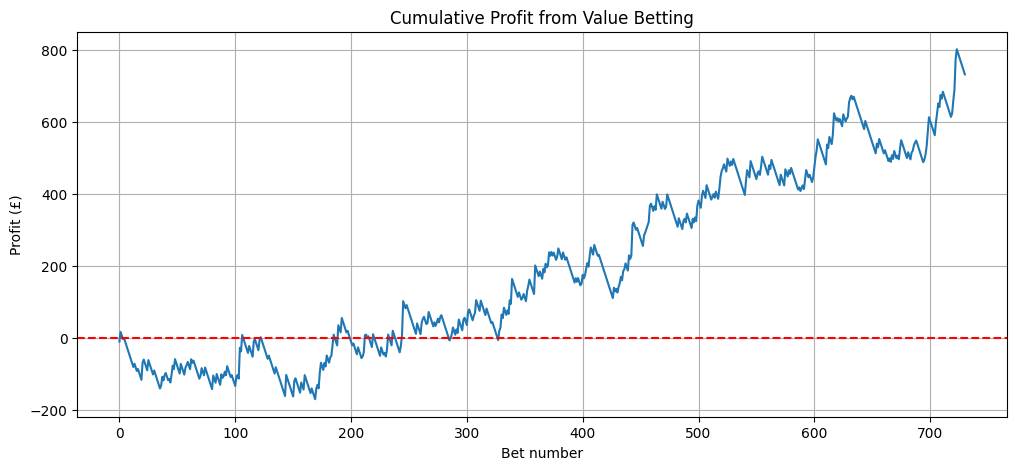

In [36]:
# Cumulative profit over time
bet_df['cumulative_profit'] = bet_df['profit'].cumsum()

plt.figure(figsize=(12, 5))
plt.plot(bet_df['cumulative_profit'])
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Cumulative Profit from Value Betting')
plt.xlabel('Bet number')
plt.ylabel('Profit (£)')
plt.grid(True)
plt.show()

Starting bankroll: £1000
Final bankroll: £1360.16
Total profit: £360.16
ROI: 36.0%
Total bets: 731
Win rate: 35.0%


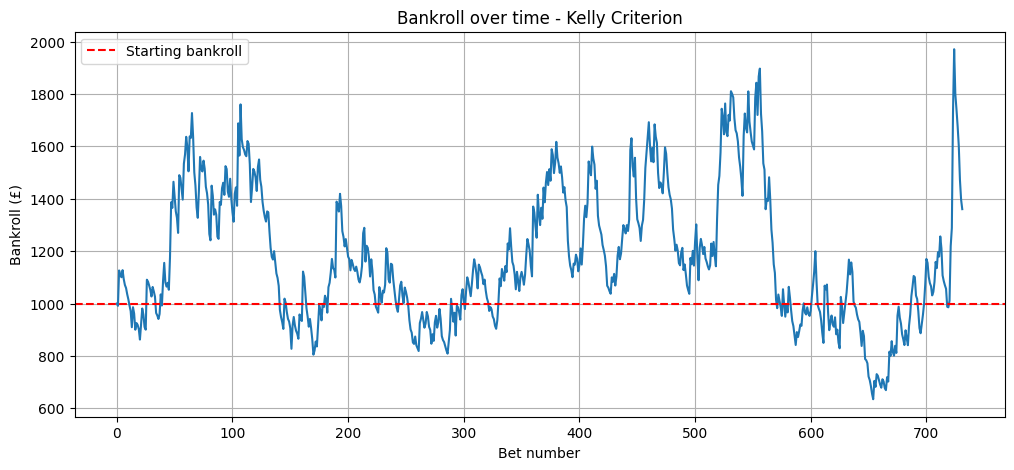

In [37]:
# Kelly Criterion bet sizing
BANKROLL = 1000  # starting bankroll £1000
VALUE_THRESHOLD = 0.05
KELLY_FRACTION = 0.25  # use quarter Kelly to be conservative

bankroll = BANKROLL
bankroll_history = [BANKROLL]
total_bets = 0
wins = 0
kelly_log = []

for _, row in results_df.iterrows():
    best_value = max(row['value_h'], row['value_d'], row['value_a'])
    
    if best_value < VALUE_THRESHOLD:
        continue
    
    # Determine bet
    if best_value == row['value_h']:
        bet_on = 'H'
        odds = row['odds_h']
        prob = row['model_prob_h']
    elif best_value == row['value_d']:
        bet_on = 'D'
        odds = row['odds_d']
        prob = row['model_prob_d']
    else:
        bet_on = 'A'
        odds = row['odds_a']
        prob = row['model_prob_a']
    
    # Kelly stake
    kelly = (prob * odds - 1) / (odds - 1)
    kelly = max(0, kelly)  # never negative
    stake = bankroll * kelly * KELLY_FRACTION
    stake = min(stake, bankroll * 0.1)  # never bet more than 10% of bankroll
    
    # Calculate profit/loss
    if bet_on == row['actual']:
        profit = stake * (odds - 1)
        wins += 1
    else:
        profit = -stake
    
    bankroll += profit
    total_bets += 1
    bankroll_history.append(bankroll)
    
    kelly_log.append({
        'bet_on': bet_on,
        'actual': row['actual'],
        'odds': odds,
        'stake': stake,
        'profit': profit,
        'bankroll': bankroll
    })

kelly_df = pd.DataFrame(kelly_log)

print(f"Starting bankroll: £{BANKROLL}")
print(f"Final bankroll: £{bankroll:.2f}")
print(f"Total profit: £{bankroll - BANKROLL:.2f}")
print(f"ROI: {(bankroll - BANKROLL)/BANKROLL*100:.1f}%")
print(f"Total bets: {total_bets}")
print(f"Win rate: {wins/total_bets*100:.1f}%")

# Plot bankroll over time
plt.figure(figsize=(12, 5))
plt.plot(bankroll_history)
plt.axhline(y=BANKROLL, color='r', linestyle='--', label='Starting bankroll')
plt.title('Bankroll over time - Kelly Criterion')
plt.xlabel('Bet number')
plt.ylabel('Bankroll (£)')
plt.legend()
plt.grid(True)
plt.show()

In [38]:
import joblib

# Save the Random Forest model
joblib.dump(rf4, '../models/random_forest.pkl')

# Save the scaler
joblib.dump(scaler, '../models/scaler.pkl')

# Save the label encoder
joblib.dump(le, '../models/label_encoder.pkl')

print("Models saved!")

Models saved!
